# 01c_scalability: Spark và pandas ở 10%, 50%, 100% dữ liệu

**Câu hỏi:** khi dữ liệu tăng từ 10% lên 100%, thời gian và RAM của Spark và pandas tăng thế nào?

**Workload giống nhau cho cả hai công cụ** (bước ETL thật của đồ án):
1. Đọc các file CSV gốc của N-BaIoT
2. Gắn nhãn `device_id`, `family`, `attack_type`, `label` từ tên file
3. Ghi ra Parquet
4. Tổng hợp: số dòng và trung bình 115 đặc trưng theo (thiết bị, họ tấn công)

**Cách đo:**
- Tập 10% và 50% lấy **phần đầu của mọi file** (mỗi file góp đúng tỷ lệ), nên cơ cấu thiết bị và loại tấn công giữ nguyên.
  Tập 100% là file gốc.
- **Mỗi lần chạy là một tiến trình riêng.** Nếu pandas hết RAM, chỉ tiến trình đó bị dừng và được ghi là "hết RAM",
  notebook vẫn chạy tiếp.
- RAM đỉnh = tổng RAM của tiến trình và các tiến trình con (với Spark là JVM), lấy mẫu mỗi 0,2 giây.
- Spark chạy `local[*]` (mọi lõi CPU của máy Kaggle); pandas chạy một luồng.

**Trước khi chạy:** gắn dataset *N-BaIoT Dataset to Detect IoT Botnet Attacks*, bật **Internet: On**, Accelerator **None**.
Thời gian khoảng 30–40 phút với `REPEAT = 1`.

## 0. Cấu hình

In [1]:
import os, re, glob, json, time, math, shutil, subprocess, sys, platform
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
import numpy as np, pandas as pd, psutil
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

FRACTIONS = [0.10, 0.50, 1.00]
REPEAT = 1                  # số lần lặp mỗi cấu hình; 2 nếu còn thời gian (lấy trung vị)
SPARK_MEM = os.environ.get("NBAIOT_SPARK_MEM", "16g")
RUN_TIMEOUT = 45 * 60       # giây, dừng một lần chạy nếu quá lâu

ROOT = os.environ.get("NBAIOT_ROOT")
if not ROOT:
    found = glob.glob("/kaggle/input/**/device_info.csv", recursive=True)
    assert found, "Chưa gắn dataset N-BaIoT: + Add Input → 'N-BaIoT Dataset to Detect IoT Botnet Attacks'"
    ROOT = os.path.dirname(found[0])
WORK = os.environ.get("NBAIOT_WORK", "/kaggle/working")
RES = f"{WORK}/results"; os.makedirs(RES, exist_ok=True)

# Thư mục tạm cho tập con CSV và output trung gian (KHÔNG để trong /kaggle/working để khỏi bị lưu vào Output)
csv_bytes = sum(os.path.getsize(p) for p in glob.glob(f"{ROOT}/*.csv"))
need = csv_bytes * 0.6 + 6e9
TMP = os.environ.get("NBAIOT_TMP") or next(
    (d for d in ["/tmp/nbaiot_bench", "/kaggle/tmp/nbaiot_bench", f"{WORK}/_bench_tmp"]
     if shutil.disk_usage(os.path.dirname(d) if os.path.exists(os.path.dirname(d)) else "/").free > need),
    f"{WORK}/_bench_tmp")
os.makedirs(TMP, exist_ok=True)

env = {"ngay_chay": time.strftime("%Y-%m-%d %H:%M"), "python": platform.python_version(),
       "pyspark": pyspark.__version__, "pandas": pd.__version__, "cpu_cores": os.cpu_count(),
       "ram_total_GB": round(psutil.virtual_memory().total / 1e9, 1), "spark_driver_memory": SPARK_MEM,
       "thu_muc_tam": TMP, "dung_luong_trong_GB": round(shutil.disk_usage(TMP).free / 1e9, 1)}
pd.Series(env)

ngay_chay               2026-11-07 13:01
python                           3.13.18
pyspark                            4.0.4
pandas                             2.3.3
cpu_cores                              4
ram_total_GB                        33.7
spark_driver_memory                  16g
thu_muc_tam            /tmp/nbaiot_bench
dung_luong_trong_GB               1038.2
dtype: object

## 1. Tạo tập con 10% và 50% (phần đầu của mọi file)

In [2]:
PAT = re.compile(r"^(\d+)\.(benign|gafgyt|mirai)(?:\.(\w+))?\.csv$")
files = sorted(f for f in os.listdir(ROOT) if PAT.match(f))
ref = pd.read_csv(f"{ROOT}/data_summary.csv", skipinitialspace=True)
ref.columns = ["file", "rows", "n_feat"]
rows_of = dict(zip(ref.file, ref.rows))

DATA_DIRS = {}
for f in FRACTIONS:
    if f >= 1.0:
        DATA_DIRS[f] = ROOT
        continue
    d = f"{TMP}/csv_{int(f*100)}pct"
    os.makedirs(d, exist_ok=True)
    t0 = time.time()
    for name in files:
        k = math.ceil(rows_of[name] * f)
        with open(f"{ROOT}/{name}") as src, open(f"{d}/{name}", "w") as dst:
            for i, line in enumerate(src):
                if i > k:              # dòng 0 là header
                    break
                dst.write(line)
    DATA_DIRS[f] = d
    print(f"{int(f*100):3d}%: {sum(math.ceil(rows_of[n]*f) for n in files):>10,} dòng | "
          f"{sum(os.path.getsize(f'{d}/{n}') for n in files)/1e9:.2f} GB | tạo trong {time.time()-t0:.0f} s")
print(f"100%: {sum(rows_of[n] for n in files):>10,} dòng | {sum(os.path.getsize(f'{ROOT}/{n}') for n in files)/1e9:.2f} GB (file gốc)")

 10%:    706,299 dòng | 0.81 GB | tạo trong 25 s
 50%:  3,531,324 dòng | 4.04 GB | tạo trong 55 s
100%:  7,062,606 dòng | 8.14 GB (file gốc)


## 2. Chương trình chạy một lần đo (ghi ra file, chạy trong tiến trình riêng)

In [3]:
WORKER = f"{TMP}/bench_worker.py"
with open(WORKER, "w", encoding="utf-8") as fh:
    fh.write(r"""
import os, re, sys, json, time, warnings
warnings.filterwarnings("ignore")
tool, data_dir, out_dir, spark_mem = sys.argv[1:5]
PAT = re.compile(r"^(\d+)\.(benign|gafgyt|mirai)(?:\.(\w+))?\.csv$")
files = sorted(f for f in os.listdir(data_dir) if PAT.match(f))
paths = [os.path.join(data_dir, f) for f in files]
raw_cols = open(paths[0]).readline().strip().split(",")
FEAT = [c.replace(".", "_") for c in raw_cols]
res = {"tool": tool}
t0 = time.time()

if tool == "pandas":
    import numpy as np, pandas as pd
    parts = []
    for f, p in zip(files, paths):
        dev, fam, att = PAT.match(f).groups()
        d = pd.read_csv(p, dtype=np.float64)
        d.columns = FEAT
        lab = pd.DataFrame({"device_id": int(dev), "family": fam, "attack_type": att or "none",
                            "label": int(fam != "benign")}, index=d.index)
        parts.append(pd.concat([d, lab], axis=1))
    df = pd.concat(parts, ignore_index=True); del parts
    res["giay_doc"] = time.time() - t0
    t1 = time.time()
    df.to_parquet(os.path.join(out_dir, "data.parquet"), index=False)
    res["giay_ghi"] = time.time() - t1
    t2 = time.time()
    agg = df.groupby(["device_id", "family"])[FEAT].mean()
    agg["n"] = df.groupby(["device_id", "family"]).size()
    res["giay_tong_hop"] = time.time() - t2
    res["so_dong"] = int(len(df)); res["so_nhom"] = int(len(agg))
else:
    from pyspark.sql import SparkSession, functions as F, types as T
    spark = (SparkSession.builder.appName("bench").master("local[*]")
             .config("spark.driver.memory", spark_mem)
             .config("spark.sql.shuffle.partitions", "16").getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    res["giay_khoi_dong"] = time.time() - t0
    schema = T.StructType([T.StructField(c, T.DoubleType()) for c in raw_cols])
    src = F.input_file_name()
    fam = F.regexp_extract(src, r"/\d+\.(benign|gafgyt|mirai)[^/]*\.csv$", 1)
    t1 = time.time()
    (spark.read.option("header", True).schema(schema).csv(paths).toDF(*FEAT)
        .withColumn("device_id", F.regexp_extract(src, r"/(\d+)\.(?:benign|gafgyt|mirai)[^/]*\.csv$", 1).cast("int"))
        .withColumn("family", fam)
        .withColumn("attack_type", F.when(fam == "benign", F.lit("none"))
                    .otherwise(F.regexp_extract(src, r"/\d+\.(?:gafgyt|mirai)\.(\w+)\.csv$", 1)))
        .withColumn("label", F.when(fam == "benign", 0).otherwise(1))
        .write.mode("overwrite").partitionBy("device_id").parquet(os.path.join(out_dir, "data")))
    res["giay_doc_ghi"] = time.time() - t1          # Spark lười: đọc và ghi diễn ra trong cùng một lệnh
    t2 = time.time()
    pq = spark.read.parquet(os.path.join(out_dir, "data"))
    agg = pq.groupBy("device_id", "family").agg(F.count("*").alias("n"), *[F.avg(c) for c in FEAT]).collect()
    res["giay_tong_hop"] = time.time() - t2
    res["so_dong"] = int(sum(r["n"] for r in agg)); res["so_nhom"] = len(agg)
    spark.stop()

res["giay_ben_trong"] = time.time() - t0
print("RESULT_JSON " + json.dumps(res))
""")
print("Đã ghi", WORKER)

Đã ghi /tmp/nbaiot_bench/bench_worker.py


## 3. Chạy đo: mỗi (công cụ, tỷ lệ) là một tiến trình riêng

In [4]:
def tree_rss(proc):
    tot = 0
    for p in [proc] + proc.children(recursive=True):
        try:
            tot += p.memory_info().rss
        except psutil.Error:
            pass
    return tot

def run_once(tool, frac):
    out = f"{TMP}/out_{tool}_{frac if isinstance(frac, str) else int(frac*100)}"
    shutil.rmtree(out, ignore_errors=True); os.makedirs(out)
    t0 = time.time()
    # Ghi output ra file, KHÔNG dùng PIPE: cảnh báo nhiều sẽ làm đầy bộ đệm và treo tiến trình con
    f_out, f_err = open(f"{out}.stdout", "w"), open(f"{out}.stderr", "w")
    p = subprocess.Popen([sys.executable, WORKER, tool, DATA_DIRS[frac], out, SPARK_MEM],
                         stdout=f_out, stderr=f_err, text=True)
    ps, peak = psutil.Process(p.pid), 0
    while p.poll() is None:
        peak = max(peak, tree_rss(ps))
        if time.time() - t0 > RUN_TIMEOUT:
            p.kill(); break
        time.sleep(0.2)
    p.wait(); wall = time.time() - t0
    f_out.close(); f_err.close()
    stdout, stderr = open(f"{out}.stdout").read(), open(f"{out}.stderr").read()
    os.remove(f"{out}.stdout"); os.remove(f"{out}.stderr")
    shutil.rmtree(out, ignore_errors=True)
    rec = {"cong_cu": tool, "ty_le": frac, "giay_tong": round(wall, 1), "ram_dinh_GB": round(peak / 1e9, 2)}
    line = [l for l in stdout.splitlines() if l.startswith("RESULT_JSON ")]
    if p.returncode == 0 and line:
        rec.update({k: (round(v, 1) if isinstance(v, float) else v)
                    for k, v in json.loads(line[0][12:]).items() if k != "tool"})
        rec["trang_thai"] = "OK"
    elif p.returncode in (-9, 137) or "MemoryError" in stderr:
        rec["trang_thai"] = "hết RAM"
    elif wall > RUN_TIMEOUT:
        rec["trang_thai"] = "quá thời gian"
    else:
        rec["trang_thai"] = f"lỗi ({p.returncode})"
        print(stderr[-1500:])
    return rec

# Chạy khởi động (không tính): JVM và thư viện được nạp lần đầu chậm hơn hẳn các lần sau.
# Nếu không có bước này, chi phí khởi động lạnh sẽ đổ hết vào mức 10% đầu tiên.
WARM = f"{TMP}/csv_warmup"; os.makedirs(WARM, exist_ok=True)
for name in files[:3]:
    with open(f"{ROOT}/{name}") as src, open(f"{WARM}/{name}", "w") as dst:
        for i, line in enumerate(src):
            if i > 200: break
            dst.write(line)
DATA_DIRS["warmup"] = WARM
for tool in ["pandas", "spark"]:
    w = run_once(tool, "warmup")
    print(f"Khởi động {tool}: {w['giay_tong']:.1f} s ({w['trang_thai']}), không tính vào kết quả")

runs = []
for tool in ["pandas", "spark"]:
    for frac in FRACTIONS:
        for i in range(1, REPEAT + 1):
            r = run_once(tool, frac); r["lan"] = i; runs.append(r)
            print(f"{tool:6s} {int(frac*100):3d}% lần {i}: {r['giay_tong']:7.1f} s | RAM đỉnh {r['ram_dinh_GB']:5.2f} GB "
                  f"| {r.get('so_dong', '-'):>9} dòng | {r['trang_thai']}")
runs = pd.DataFrame(runs)
runs.to_csv(f"{RES}/scalability_chi_tiet.csv", index=False)

Khởi động pandas: 1.0 s (OK), không tính vào kết quả
Khởi động spark: 30.6 s (OK), không tính vào kết quả
pandas  10% lần 1:    20.9 s | RAM đỉnh  1.54 GB |    706299 dòng | OK
pandas  50% lần 1:    91.7 s | RAM đỉnh  6.78 GB |   3531324 dòng | OK
pandas 100% lần 1:   255.4 s | RAM đỉnh 13.64 GB |   7062606 dòng | OK
spark   10% lần 1:    68.0 s | RAM đỉnh  3.21 GB |    706299 dòng | OK
spark   50% lần 1:   183.2 s | RAM đỉnh  5.98 GB |   3531324 dòng | OK
spark  100% lần 1:   357.2 s | RAM đỉnh  4.59 GB |   7062606 dòng | OK


## 4. Bảng kết quả (dán vào sheet "Số liệu")

In [5]:
ok = runs[runs.trang_thai == "OK"]
num = [c for c in ["so_dong", "giay_tong", "giay_khoi_dong", "giay_doc", "giay_ghi", "giay_doc_ghi",
                   "giay_tong_hop", "ram_dinh_GB"] if c in runs]
table = (runs.groupby(["cong_cu", "ty_le"])
             .agg(**{c: (c, "median") for c in num}, trang_thai=("trang_thai", "first"))
             .reset_index())
table["dong_moi_giay"] = (table.so_dong / table.giay_tong).round(0)
table["ty_le"] = (table.ty_le * 100).astype(int).astype(str) + "%"
table.to_csv(f"{RES}/scalability.csv", index=False)

wide = table.pivot(index="ty_le", columns="cong_cu", values=["giay_tong", "ram_dinh_GB"])
wide = wide.reindex([f"{int(f*100)}%" for f in FRACTIONS])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
if {"giay_tong_pandas", "giay_tong_spark"} <= set(wide.columns):
    wide["spark_nhanh_hon_x_lan"] = (wide.giay_tong_pandas / wide.giay_tong_spark).round(2)
wide.to_csv(f"{RES}/scalability_so_sanh.csv")

print(table.to_string(index=False))
print(); print(wide.to_string())

# Mức tăng khi dữ liệu tăng 10 lần (10% -> 100%): tăng tuyến tính lý tưởng là 10×
for tool in ["pandas", "spark"]:
    t = table[(table.cong_cu == tool) & (table.trang_thai == "OK")].set_index("ty_le")
    if {"10%", "100%"} <= set(t.index):
        print(f"{tool}: thời gian ×{t.loc['100%','giay_tong']/t.loc['10%','giay_tong']:.1f}, "
              f"RAM ×{t.loc['100%','ram_dinh_GB']/t.loc['10%','ram_dinh_GB']:.1f} khi dữ liệu ×10")

cong_cu ty_le   so_dong  giay_tong  giay_khoi_dong  giay_doc  giay_ghi  giay_doc_ghi  giay_tong_hop  ram_dinh_GB trang_thai  dong_moi_giay
 pandas   10%  706299.0       20.9             NaN      15.7       3.9           NaN            0.9         1.54         OK        33794.0
 pandas   50% 3531324.0       91.7             NaN      70.4      17.8           NaN            3.1         6.78         OK        38510.0
 pandas  100% 7062606.0      255.4             NaN     207.0      40.5           NaN            7.3        13.64         OK        27653.0
  spark   10%  706299.0       68.0             9.0       NaN       NaN          43.9           13.6         3.21         OK        10387.0
  spark   50% 3531324.0      183.2             8.5       NaN       NaN         139.6           33.5         5.98         OK        19276.0
  spark  100% 7062606.0      357.2             8.6       NaN       NaN         286.1           60.8         4.59         OK        19772.0

       giay_tong_pandas  g

## 5. Biểu đồ scalability

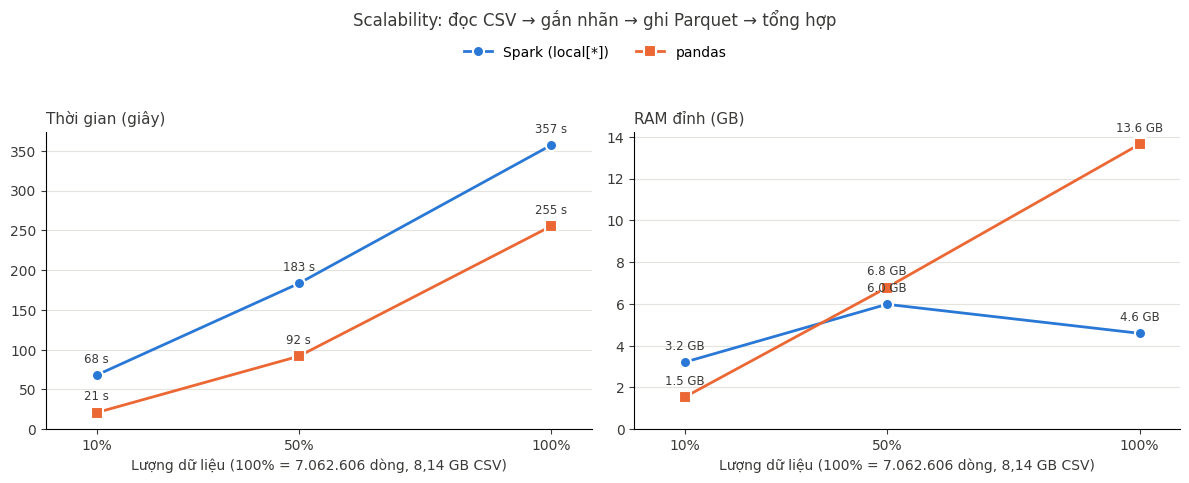

In [6]:
from matplotlib.ticker import FuncFormatter
BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#3a3a38", "#e4e3dd"
STYLE = {"spark": (BLUE, "o", "Spark (local[*])"), "pandas": (ORANGE, "s", "pandas")}
xs = [f * 100 for f in FRACTIONS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, col, ylab, fmt in [(axes[0], "giay_tong", "Thời gian (giây)", "{:.0f} s"),
                           (axes[1], "ram_dinh_GB", "RAM đỉnh (GB)", "{:.1f} GB")]:
    for tool, (c, m, name) in STYLE.items():
        d = runs[runs.cong_cu == tool].groupby("ty_le").agg(v=(col, "median"), st=("trang_thai", "first"))
        d = d.reindex(FRACTIONS)
        okm = d.st == "OK"
        ax.plot(np.array(xs)[okm.values], d.v[okm], color=c, marker=m, lw=2, ms=8, label=name,
                markeredgecolor="white", markeredgewidth=1.5)
        for x, (v, st) in zip(xs, d.itertuples(index=False)):
            if st == "OK":
                ax.annotate(fmt.format(v), (x, v), xytext=(0, 9), textcoords="offset points",
                            ha="center", fontsize=8.5, color=INK)
            elif isinstance(st, str):
                ax.annotate(f"{name.split()[0]}: {st}", (x, 0), xycoords=("data", "axes fraction"),
                            xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9,
                            color=INK, fontweight="bold")
    ax.set_xticks(xs, [f"{int(x)}%" for x in xs])
    ax.set_xlim(0, 108); ax.set_ylim(bottom=0)
    ax.set_xlabel("Lượng dữ liệu (100% = 7.062.606 dòng, 8,14 GB CSV)", color=INK)
    ax.set_title(ylab, color=INK, fontsize=11, loc="left")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
    ax.tick_params(colors=INK)
fig.suptitle("Scalability: đọc CSV → gắn nhãn → ghi Parquet → tổng hợp", color=INK, fontsize=12, y=1.04)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(f"{RES}/scalability.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Dọn thư mục tạm

In [7]:
shutil.rmtree(TMP, ignore_errors=True)
print("Đã xoá", TMP)
print("Kết quả:", sorted(f for f in os.listdir(RES) if f.startswith("scalability")))

Đã xoá /tmp/nbaiot_bench
Kết quả: ['scalability.csv', 'scalability.png', 'scalability_chi_tiet.csv', 'scalability_so_sanh.csv']


## 7. Đọc kết quả cho báo cáo

- **Thời gian:** so sánh mức tăng khi dữ liệu ×10 (từ 10% lên 100%). Tăng gần 10× là tuyến tính, nghĩa là công cụ
  mở rộng tốt. Spark có chi phí khởi động cố định (`giay_khoi_dong`) nên ở 10% có thể không nhanh hơn pandas;
  lợi thế xuất hiện khi dữ liệu lớn.
- **RAM:** pandas phải nạp **toàn bộ** dữ liệu vào bộ nhớ, nên RAM tăng gần tuyến tính theo dữ liệu. Spark xử lý theo
  từng partition, RAM bị chặn bởi `spark.driver.memory` chứ không theo kích thước dữ liệu. Đây là lý do chính để dùng
  Spark khi dữ liệu vượt RAM của một máy.
- **Giới hạn cần ghi rõ:** Spark chạy `local[*]` trên một máy Kaggle, không phải cụm nhiều node; pandas chạy một luồng.